# Garimpo supply and the gold price

Does garimpo respond to the gold price where there is gold geology? This is the first
check of lead 1's supply equation (`output/research/mining_economics_leads.md`, lead 1
and Evidence E10):

- **Exposure:** the municipality's own never-exploited SGB gold occurrences (binary;
  `geology_adm2`), the predetermined part of the geology, times the log annual gold
  price in BRL.
- **Outcomes:** the C11 garimpo share of the municipality's own trenches (gold, and all
  substances; pp, 2004–2019, before the 2020 reclassification step), and SIVEP garimpo
  malaria cases by infection municipality (2004–2024): all, local and incoming workers,
  and any case. Non-garimpo malaria is the outcome placebo, tin occurrences the
  exposure placebo.
- **Model:** the Legal Amazon, municipality and year FE, unweighted.
- **Inference:** Otto-3 clustered SEs, the restricted wild-cluster bootstrap on Otto-3
  basins, two-way clustering by basin and year, and randomization over random-walk
  price paths. The BRL price trends up and jumps in 2020, so the checks add a
  deposit-specific linear trend and the event study shows where the variation sits.

The estimators live in `src/analysis/garimpo_supply.py`. Tables are written to
`output/analysis/garimpo/price_supply/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_supply as S

warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "price_supply"
OUT.mkdir(parents=True, exist_ok=True)
COLUMNS = ["estimate", "se_basin", "p_basin", "p_wcb", "p_two_way", "p_random_walk",
           "n_obs", "n_exposed", "n_basins", "mean_y", "mean_y_exposed"]

frame = S.build_frame()
print(f"{len(frame):,} municipality-years · {frame.mun_id.nunique():,} municipalities · {frame.year.min()}–{frame.year.max()}")

16,212 municipality-years · 772 municipalities · 2004–2024


## 1. Sample and exposure

In [2]:
sample = S.sample_table(frame)
sample.to_csv(OUT / "sample.csv", header=["value"])
display(sample.to_frame("value"))

municipalities = frame.drop_duplicates("mun_id")
by_state = municipalities.groupby("state")[[S.EXPOSURE, S.ALL_GOLD_EXPOSURE, S.TIN_EXPOSURE]].sum().astype(int)
cases = frame.groupby(["state", frame[S.EXPOSURE] > 0])["inf_garimpo"].sum().unstack(fill_value=0)
by_state["garimpo cases, exposed"] = cases.get(True, 0)
by_state["garimpo cases, other"] = cases.get(False, 0)
display(by_state)

,value
Legal Amazon municipalities in the panel,772
with a never-exploited gold occurrence,74
with any gold occurrence,154
with a tin occurrence,54
Otto-3 basins,143
garimpo cases 2004-2024,2.481e+05
share in municipalities with never-exploited gold,0.8535


,gold_unexploited_any,gold_any,tin_any,"garimpo cases, exposed","garimpo cases, other"
state,,,,,
11,11,30,19,4290,1.964e+04
12,0,1,0,0,57
13,6,10,6,6232,1.131e+04
14,7,10,4,3.224e+04,1211
15,26,34,15,1.367e+05,1257
16,11,11,6,2.138e+04,288
17,3,15,2,0,8
21,1,8,0,31,578
51,9,35,2,1.085e+04,1992


**Reading the results.** 74 of the 772 Legal Amazon municipalities hold a never-exploited
gold occurrence, mostly in Pará (26), Amapá and Rondônia (11 each). They are where garimpo
is: they hold 85% of the 248,000 garimpo cases of 2004–2024, and in Pará, Roraima and
Amapá almost all of them. The geology is relevant across municipalities; the question here
is whether the price moves garimpo over time within them, which the municipality FE leave
as the only variation.

## 2. Event study

Coefficients of exposure × year (2004 omitted), municipality and year FE, Otto-3 SEs,
with the log BRL gold price for comparison; for the cases also without Roraima, where
the Yanomami garimpo rush starts in 2019.

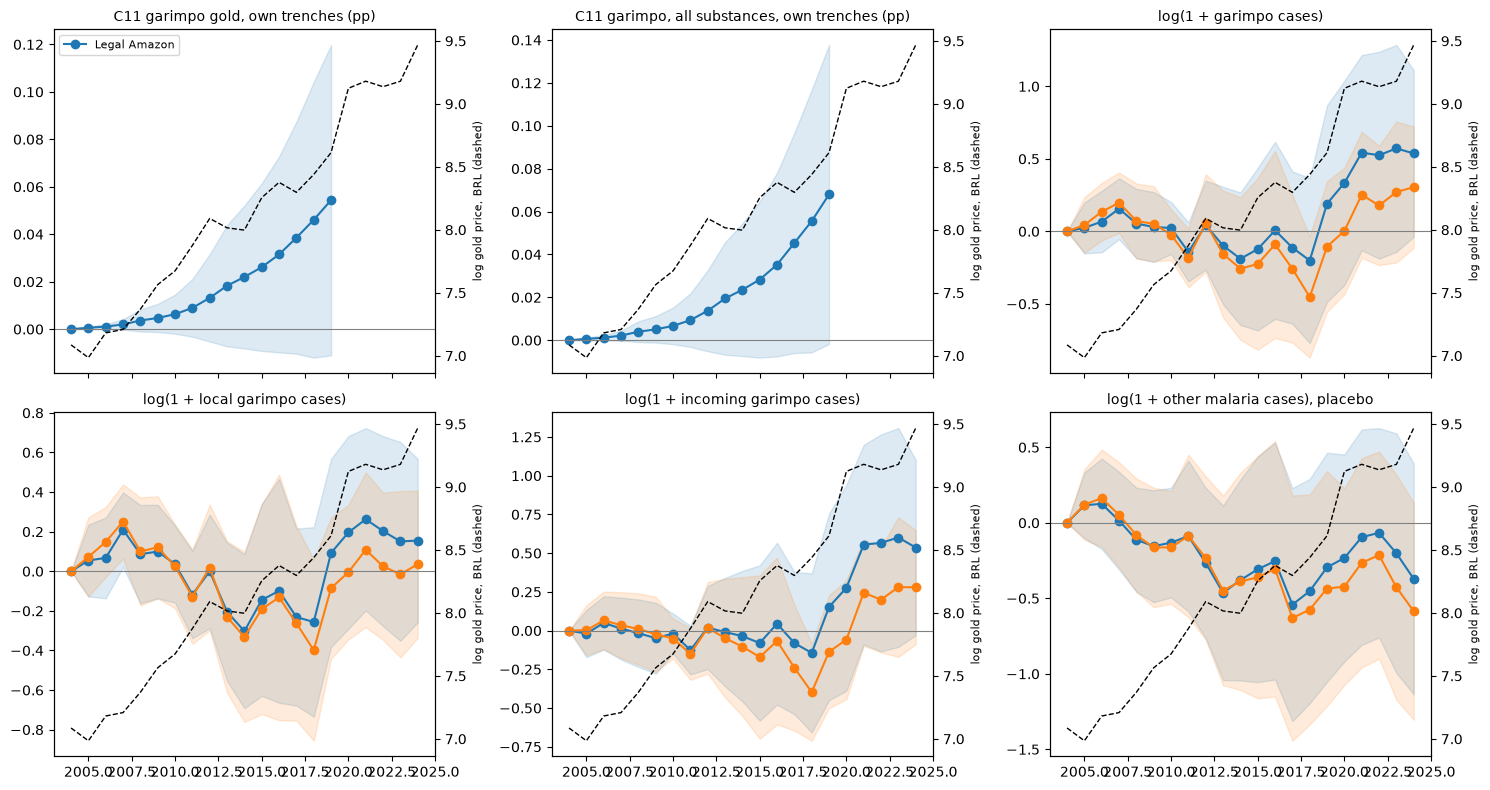

sample         Legal Amazon                                                                                                       without Roraima                                                               
outcome c11_garimpo_gold_pp c11_garimpo_pp log1p_garimpo_cases log1p_garimpo_incoming log1p_garimpo_local log1p_other_malaria log1p_garimpo_cases log1p_garimpo_incoming log1p_garimpo_local log1p_other_malaria
year                                                                                                                                                                                                            
2004                      0              0                   0                      0                   0                   0                   0                      0                   0                   0
2005                  0.001          0.001               0.024                 -0.019               0.054               0.116               0.044                  0.003               0.072                0.12
2006                  0.001          0.001               0.068                   0.05               0.068               0.126               0.135                  0.066               0.148               0.163
2007                  0.002          0.002               0.156                  0.013                0.21               0.014               0.198                  0.035               0.251               0.052
2008                  0.004          0.004               0.054                 -0.017               0.086              -0.112               0.071                   0.01                 0.1              -0.081
2009                  0.005          0.005                0.03                 -0.049                 0.1              -0.155               0.052                 -0.023               0.121              -0.163
2010                  0.006          0.007               0.024                 -0.019               0.036              -0.131              -0.023                 -0.051               0.024              -0.163
2011                  0.009          0.009              -0.142                 -0.126              -0.118              -0.088              -0.184                  -0.15              -0.128              -0.087
2012                  0.013          0.014               0.043                   0.02                  -0              -0.266               0.058                  0.018               0.019              -0.234
2013                  0.018          0.019              -0.098                 -0.009              -0.204              -0.463              -0.156                 -0.049              -0.231              -0.448
2014                  0.022          0.024              -0.189                 -0.036              -0.303              -0.379              -0.257                 -0.103              -0.331              -0.388
2015                  0.026          0.028              -0.123                  -0.08              -0.145              -0.308              -0.225                 -0.171              -0.191              -0.361
2016                  0.031          0.035               0.007                  0.045              -0.099              -0.253               -0.09                 -0.067              -0.132              -0.305
2017                  0.039          0.045              -0.112                  -0.08              -0.231              -0.542              -0.258                  -0.24              -0.262              -0.631
2018                  0.046          0.056              -0.201                 -0.144              -0.256              -0.452              -0.453                 -0.397              -0.398              -0.574
2019                  0.054          0.068               0.191                  0.153               0.093              -0.294              -0.105                 -0.136              -0.085              -0.435
2020                    NaN  

In [3]:
ES_OUTCOMES = ["c11_garimpo_gold_pp", "c11_garimpo_pp", "log1p_garimpo_cases", "log1p_garimpo_local",
               "log1p_garimpo_incoming", "log1p_other_malaria"]
studies = pd.concat(
    [S.event_study(frame, outcome).assign(sample="Legal Amazon") for outcome in ES_OUTCOMES]
    + [S.event_study(frame, outcome, drop_states=(S.RORAIMA,)).assign(sample="without Roraima")
       for outcome in ES_OUTCOMES[2:]],
    ignore_index=True,
)
studies.to_csv(OUT / "event_study.csv", index=False)
price = frame.groupby("year")[S.PRICE].first()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, outcome in zip(axes.ravel(), ES_OUTCOMES):
    for sample_name, color in (("Legal Amazon", "C0"), ("without Roraima", "C1")):
        study = studies[(studies.outcome == outcome) & (studies["sample"] == sample_name)]
        if study.empty:
            continue
        ax.plot(study.year, study.estimate, marker="o", color=color, label=sample_name)
        ax.fill_between(study.year, study.estimate - 1.96 * study.se, study.estimate + 1.96 * study.se,
                        color=color, alpha=0.15)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(S.OUTCOMES[outcome][0], fontsize=10)
    twin = ax.twinx()
    twin.plot(price.index, price, color="black", ls="--", lw=1)
    twin.set_ylabel("log gold price, BRL (dashed)", fontsize=8)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

display(studies.pivot_table(index="year", columns=["sample", "outcome"], values="estimate").round(3))

**Reading the results.** Neither outcome follows the price.
- The C11 garimpo gap between municipalities with and without never-exploited gold grows
  smoothly from 0 to 0.05 pp (gold) and 0.07 pp (all substances) over 2004–2019, including
  2012–15, when the price was flat. It is a trend, not a price response.
- Garimpo cases in exposed municipalities do not rise relative to the rest over 2004–2018,
  while the price rises by 1.3 log points; if anything they fall (−0.2 log points in 2018).
  They jump by about 0.5 log points from 2019 on, almost all in incoming workers, and stay
  there through 2024, after the 2023 suspension of the good-faith rule.
- Without Roraima the jump shrinks to 0.25–0.3 and is not significant: much of it is the
  Yanomami rush, which coincides with the 2019 collapse in enforcement as much as with the
  2020 price step.
- Other malaria in exposed municipalities drifts down relative to the rest throughout.

## 3. Price × deposits and checks

The baseline against: a deposit-specific linear trend; state×year FE with and without
it; 2004–2012, before the 2013 good-faith rule; without Roraima, with and without the
trend; the USD price; all gold occurrences and log(1 + never-exploited count) as the
exposure; and tin occurrences × price added as a placebo. Random-walk p-values for the
baseline, the trend spec and the spec without Roraima.

In [4]:
table = S.run_table(frame)
table.to_csv(OUT / "price_supply.csv", index=False)
for outcome in S.OUTCOMES:
    print(outcome)
    display(table[table.outcome == outcome].set_index(["spec", "exposure"])[COLUMNS])

c11_garimpo_gold_pp


,,estimate,se_basin,p_basin,p_wcb,p_two_way,p_random_walk,n_obs,n_exposed,n_basins,mean_y,mean_y_exposed
spec,exposure,,,,,,,,,,,
baseline,gold_unexploited_any,0.03003,0.01947,0.1252,0.0043,0.1386,0.8425,12352,74,143,0.037,0.1517
deposit trend,gold_unexploited_any,-0.02319,0.01279,0.07179,0.0037,NaN,0.4585,12352,74,143,0.037,0.1517
state x year FE,gold_unexploited_any,0.0385,0.02529,0.1302,0.005901,0.1412,NaN,12352,74,143,0.037,0.1517
state x year FE + deposit trend,gold_unexploited_any,-0.02891,0.01626,0.07759,0.004,NaN,NaN,12352,74,143,0.037,0.1517
2004-2012 (before the 2013 rule),gold_unexploited_any,0.01135,0.008101,0.1632,0.009401,0.1658,NaN,6948,74,143,0.03386,0.137
without Roraima,gold_unexploited_any,0.03358,0.02171,0.1241,0.0042,0.1375,0.843,12112,67,141,0.03773,0.1675
without Roraima + deposit trend,gold_unexploited_any,-0.02587,0.01418,0.07014,0.0036,NaN,NaN,12112,67,141,0.03773,0.1675
USD price,gold_unexploited_any,0.0236,0.01565,0.1338,0.005101,0.161,NaN,12352,74,143,0.037,0.1517
all gold occurrences,gold_any,0.01885,0.01281,0.1434,0.017,0.1555,NaN,12352,154,143,0.037,0.1214


c11_garimpo_pp


,,estimate,se_basin,p_basin,p_wcb,p_two_way,p_random_walk,n_obs,n_exposed,n_basins,mean_y,mean_y_exposed
spec,exposure,,,,,,,,,,,
baseline,gold_unexploited_any,0.03561,0.02039,0.08291,0.005201,0.1009,0.8395,12352,74,143,0.04937,0.1825
deposit trend,gold_unexploited_any,-0.03319,0.01541,0.03292,0.0012,NaN,0.446,12352,74,143,0.04937,0.1825
state x year FE,gold_unexploited_any,0.04268,0.02632,0.1071,0.0154,0.1224,NaN,12352,74,143,0.04937,0.1825
state x year FE + deposit trend,gold_unexploited_any,-0.04014,0.01852,0.03191,0.0002,NaN,NaN,12352,74,143,0.04937,0.1825
2004-2012 (before the 2013 rule),gold_unexploited_any,0.01183,0.008309,0.1566,0.0351,0.1598,NaN,6948,74,143,0.04531,0.1647
without Roraima,gold_unexploited_any,0.03984,0.02263,0.0806,0.0047,0.09846,0.8385,12112,67,141,0.05026,0.2006
without Roraima + deposit trend,gold_unexploited_any,-0.03678,0.01694,0.03157,0.0011,NaN,NaN,12112,67,141,0.05026,0.2006
USD price,gold_unexploited_any,0.02719,0.01626,0.09667,0.007401,0.1342,NaN,12352,74,143,0.04937,0.1825
all gold occurrences,gold_any,0.02273,0.01327,0.08887,0.009501,0.1055,NaN,12352,154,143,0.04937,0.1476


log1p_garimpo_cases


...

,,estimate,se_basin,p_basin,p_wcb,p_two_way,p_random_walk,n_obs,n_exposed,n_basins,mean_y,mean_y_exposed
spec,exposure,,,,,,,,,,,
baseline,gold_unexploited_any,0.2378,0.1775,0.1826,0.2432,0.1974,0.7845,16212,74,143,0.2216,1.284
deposit trend,gold_unexploited_any,0.6521,0.2373,0.006762,0.0171,0.00336,0.177,16212,74,143,0.2216,1.284
state x year FE,gold_unexploited_any,0.2197,0.1226,0.07524,0.1395,0.0905,NaN,16212,74,143,0.2216,1.284
state x year FE + deposit trend,gold_unexploited_any,0.7346,0.2442,0.003113,0.003,0.01169,NaN,16212,74,143,0.2216,1.284
2004-2012 (before the 2013 rule),gold_unexploited_any,-0.05026,0.09079,0.5807,0.594,0.5021,NaN,6948,74,143,0.2416,1.193
without Roraima,gold_unexploited_any,0.06755,0.09708,0.4877,0.5165,0.5151,0.7875,15897,67,141,0.2033,1.252
without Roraima + deposit trend,gold_unexploited_any,0.6144,0.2583,0.01874,0.0347,0.0844,NaN,15897,67,141,0.2033,1.252
USD price,gold_unexploited_any,0.2765,0.2195,0.21,0.2966,0.2407,NaN,16212,74,143,0.2216,1.284
all gold occurrences,gold_any,0.06305,0.1143,0.582,0.6691,0.5901,NaN,16212,154,143,0.2216,0.8306


any_garimpo_case


,,estimate,se_basin,p_basin,p_wcb,p_two_way,p_random_walk,n_obs,n_exposed,n_basins,mean_y,mean_y_exposed
spec,exposure,,,,,,,,,,,
baseline,gold_unexploited_any,0.05161,0.03372,0.1282,0.1792,0.1348,0.7795,16212,74,143,0.1694,0.5959
deposit trend,gold_unexploited_any,0.09659,0.08612,0.2639,0.2962,0.2034,0.127,16212,74,143,0.1694,0.5959
state x year FE,gold_unexploited_any,0.05461,0.02943,0.06562,0.07461,0.09357,NaN,16212,74,143,0.1694,0.5959
state x year FE + deposit trend,gold_unexploited_any,0.1509,0.09035,0.09706,0.1277,0.1094,NaN,16212,74,143,0.1694,0.5959
2004-2012 (before the 2013 rule),gold_unexploited_any,0.0717,0.04342,0.1009,0.1254,0.1198,NaN,6948,74,143,0.206,0.6051
without Roraima,gold_unexploited_any,0.03133,0.02963,0.2921,0.339,0.3093,0.722,15897,67,141,0.1584,0.5785
without Roraima + deposit trend,gold_unexploited_any,0.1279,0.09006,0.1577,0.187,0.1901,NaN,15897,67,141,0.1584,0.5785
USD price,gold_unexploited_any,0.08239,0.04558,0.07282,0.1042,0.08116,NaN,16212,74,143,0.1694,0.5959
all gold occurrences,gold_any,0.0004497,0.02469,0.9855,0.9847,0.9857,NaN,16212,154,143,0.1694,0.4317


log1p_other_malaria


,,estimate,se_basin,p_basin,p_wcb,p_two_way,p_random_walk,n_obs,n_exposed,n_basins,mean_y,mean_y_exposed
spec,exposure,,,,,,,,,,,
baseline,gold_unexploited_any,-0.1188,0.1693,0.4837,0.4902,0.4867,0.8515,16212,74,143,1.735,3.857
deposit trend,gold_unexploited_any,0.4915,0.3682,0.1841,0.2366,0.1087,0.212,16212,74,143,1.735,3.857
state x year FE,gold_unexploited_any,0.2153,0.1504,0.1545,0.1646,0.1829,NaN,16212,74,143,1.735,3.857
state x year FE + deposit trend,gold_unexploited_any,0.6698,0.2997,0.02697,0.037,0.1235,NaN,16212,74,143,1.735,3.857
2004-2012 (before the 2013 rule),gold_unexploited_any,-0.2962,0.1984,0.1376,0.1698,0.1337,NaN,6948,74,143,2.438,4.69
without Roraima,gold_unexploited_any,-0.2239,0.1563,0.1542,0.1613,0.1619,0.843,15897,67,141,1.647,3.567
without Roraima + deposit trend,gold_unexploited_any,0.4375,0.4047,0.2815,0.3371,0.2055,NaN,15897,67,141,1.647,3.567
USD price,gold_unexploited_any,-0.2291,0.234,0.3292,0.3446,0.3154,NaN,16212,74,143,1.735,3.857
all gold occurrences,gold_any,-0.1264,0.1261,0.318,0.3258,0.334,NaN,16212,154,143,1.735,2.9


**Reading the results.** There is no price response in the specification lead 1 needs.
- Baseline (municipality and year FE): C11 garimpo gold +0.030 pp per log point (Otto-3
  p 0.13), garimpo cases +0.21 log points (p 0.26), with random-walk p-values of 0.78–0.85
  for every outcome. Without Roraima the case coefficient is 0.04 (p 0.71). Before the 2013
  rule, when the price rose fastest, it is −0.08 (p 0.47).
- With a deposit-specific trend, the C11 coefficients turn negative and the case
  coefficients rise to 0.65–0.86 (Otto-3 p 0.003–0.06). That coefficient measures the deviation of
  cases from a linear trend, which is the post-2019 break; the outcome placebo, other
  malaria, rises with it (0.49–0.67, p 0.03 with state×year FE), and the random-walk p is
  0.12–0.18. It is not a price elasticity.
- The tin placebo is negative (−0.37 on cases, p 0.07).
- The wild-cluster bootstrap gives p ≈ 0.005 for the C11 outcomes in every specification,
  including those where the coefficient changes sign. With 74 exposed municipalities in few
  basins and an outcome that is zero almost everywhere else, the restricted bootstrap
  over-rejects; the Otto-3 and random-walk p-values are the ones to read.

Read together: the gold geology locates garimpo, but within municipalities garimpo follows
a smooth trend (C11) and a post-2019 break concentrated in Roraima (SIVEP), not the gold
price. A price-based supply elasticity is not identified from this variation; the 2019–2023
policy changes are the shocks the data respond to.

In [5]:
main = table[table.exposure == S.EXPOSURE]
display(main.pivot_table(index="spec", columns="outcome", values="estimate", sort=False).round(3))
display(main.pivot_table(index="spec", columns="outcome", values="p_basin", sort=False).round(3))

outcome,c11_garimpo_gold_pp,c11_garimpo_pp,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria
spec,,,,,,,
baseline,0.03,0.036,0.21,0.047,0.238,0.052,-0.119
deposit trend,-0.023,-0.033,0.773,0.654,0.652,0.097,0.491
state x year FE,0.038,0.043,0.207,0.057,0.22,0.055,0.215
state x year FE + deposit trend,-0.029,-0.04,0.856,0.717,0.735,0.151,0.67
2004-2012 (before the 2013 rule),0.011,0.012,-0.083,-0.115,-0.05,0.072,-0.296
without Roraima,0.034,0.04,0.044,-0.05,0.068,0.031,-0.224
without Roraima + deposit trend,-0.026,-0.037,0.748,0.608,0.614,0.128,0.438
USD price,0.024,0.027,0.231,0.021,0.276,0.082,-0.229
placebo: + tin,0.037,0.039,0.342,0.173,0.351,0.069,-0.03


outcome,c11_garimpo_gold_pp,c11_garimpo_pp,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria
spec,,,,,,,
baseline,0.125,0.083,0.26,0.707,0.183,0.128,0.484
deposit trend,0.072,0.033,0.012,0.028,0.007,0.264,0.184
state x year FE,0.13,0.107,0.131,0.587,0.075,0.066,0.154
state x year FE + deposit trend,0.078,0.032,0.011,0.028,0.003,0.097,0.027
2004-2012 (before the 2013 rule),0.163,0.157,0.469,0.276,0.581,0.101,0.138
without Roraima,0.124,0.081,0.705,0.596,0.488,0.292,0.154
without Roraima + deposit trend,0.07,0.032,0.026,0.057,0.019,0.158,0.282
USD price,0.134,0.097,0.322,0.893,0.21,0.073,0.329
placebo: + tin,0.155,0.148,0.056,0.2,0.031,0.039,0.864
